---
# <div align="center"><font color='blue'> COSC 2779/2972 | Deep Learning </font></div>
## <div align="center"><font color='blue'> Week 10 Lab: Unsupervised Learning & Generative Models</font></div>
---

So far, most models in this course have learned a mapping from **input → label** (supervised learning). But modern AI systems can also learn without labels: compressing data, discovering hidden structure, and generating entirely new samples.

This week we explore three families of generative models, each with a different philosophy:

| Model | Core Idea | Learns By |
|---|---|---|
| **Autoencoder** | Compress and reconstruct | Minimising reconstruction error |
| **GAN** | Adversarial game | Generator tries to fool discriminator |
| **Diffusion** | Denoise step by step | Learning to reverse a noise process |

We use **FashionMNIST** throughout, it's small enough to train quickly but visually rich enough to see interesting results.



## 🎯 Learning Objectives

By the end of this lab, you should be able to:

- Explain the difference between supervised learning, unsupervised learning, and generative modelling
- Build and train convolutional autoencoders and understand latent representations
- Investigate the compression vs reconstruction trade-off
- Train and analyse a simple GAN, including diagnosing failure modes
- Understand the core ideas behind diffusion models through a denoising autoencoder
- Compare autoencoders, GANs, and diffusion models
- Visualise and explore latent spaces

**Prerequisites:** Weeks 3–9 (CNNs, transfer learning, transformers, foundation models)

**Duration:** ~2–3 hours

---

## Setup

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import TSNE

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


### Load FashionMNIST

In [ ]:
transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

CLASS_NAMES = train_dataset.classes
print(f'Training: {len(train_dataset)}, Test: {len(test_dataset)}')
print(f'Classes: {CLASS_NAMES}')
print(f'Image shape: {train_dataset[0][0].shape}')

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 212kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.93MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.7MB/s]

Training: 60000, Test: 10000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Image shape: torch.Size([1, 28, 28])


👉 Note: The train/validation/test split framework from previous weeks still applies to unsupervised learning. You train on the training set (to update model parameters), tune hyperparameters using the validation set (e.g., latent dimension, learning rate, noise level), and evaluate final performance on the held-out test set. The only difference is that no labels are used during training — the images themselves are both the input and the target. 

For this lab we skip the validation split to keep things simple, but in any practical application you should always maintain a proper train/val/test split.

---
# Part: Supervised vs Unsupervised vs Generative

| Paradigm | Input | Goal | Example |
|---|---|---|---|
| **Supervised** | (x, y) pairs | Learn x → y | Image classification |
| **Unsupervised** | x only (no labels) | Find structure in x | Clustering, compression |
| **Generative** | x only | Model p(x), generate new samples | Image synthesis |

Why does this matter?
- Labelled data is expensive — unsupervised methods learn from raw data
- Generative models can create training data, augment datasets, and enable creative applications
- Latent representations learned by generative models are useful for downstream tasks (representation learning)

### 🤔 Questions

1. Why is labelled data expensive to obtain? Give examples from different domains.
2. What applications require generating new data rather than classifying existing data?
3. Can you think of a task where unsupervised learning would be more appropriate than supervised learning?

*Double-click here to write your answers...*

---
# Part 2: Data Exploration 

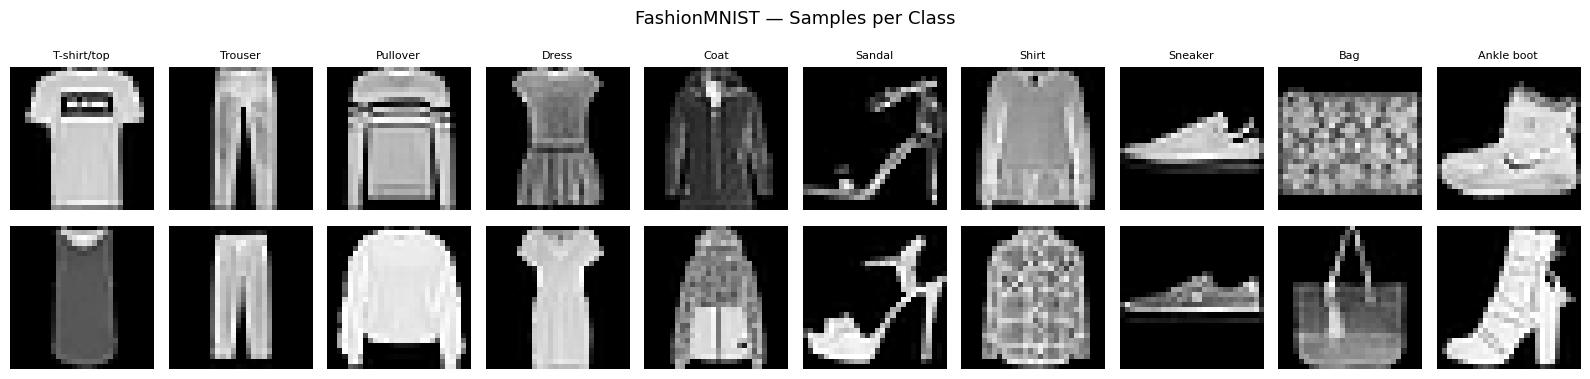

In [3]:
# Show samples from each class
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
fig.suptitle('FashionMNIST — Samples per Class', fontsize=13)

class_samples = {i: [] for i in range(10)}
for img, label in train_dataset:
    if len(class_samples[label]) < 2:
        class_samples[label].append(img)
    if all(len(v) >= 2 for v in class_samples.values()):
        break

for col in range(10):
    for row in range(2):
        axes[row, col].imshow(class_samples[col][row].squeeze(), cmap='gray')
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(CLASS_NAMES[col], fontsize=8)
plt.tight_layout()
plt.show()

### 🤔 Questions

1. Which classes appear visually similar? (e.g., Shirt vs T-shirt, Pullover vs Coat)
2. Which classes might be hardest for a generative model to produce? Why?
3. Why might FashionMNIST be more interesting than MNIST digits for generative modelling?

*Double-click here to write your answers...*

---
# Part 3: Autoencoders

## The Core Idea

An autoencoder learns to **compress** data into a small latent vector and then **reconstruct** it:

```
Image (28×28=784 pixels)
  → Encoder → Latent Vector (e.g., 32 numbers)
  → Decoder → Reconstructed Image (28×28)
```

The bottleneck forces the network to learn a **compressed representation** — it must figure out which information is essential and discard the rest. This is unsupervised: no labels are used, only the images themselves.

**Loss function:** Mean Squared Error between the input and reconstruction:

$$\mathcal{L} = \frac{1}{N} \sum_{i=1}^{N} ||x_i - \hat{x}_i||^2$$

## Task 3.1 — Build a Convolutional Autoencoder

In [4]:
class Reshape(nn.Module):
    """Helper module to reshape tensors inside nn.Sequential."""
    def __init__(self, *shape):
        super().__init__()
        self.shape = shape
    def forward(self, x):
        return x.view(x.size(0), *self.shape)


class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        
        # Encoder: (1, 28, 28) → (32, 7, 7) → latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),  # (16, 14, 14)
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1), # (32, 7, 7)
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, latent_dim),
        )
        
        # Decoder: latent_dim → (32, 7, 7) → (1, 28, 28)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32 * 7 * 7),
            nn.ReLU(),
            Reshape(32, 7, 7),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),  # (16, 14, 14)
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),   # (1, 28, 28)
            nn.Sigmoid(),  # output pixel values in [0, 1]
        )
    
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)
    
    def encode(self, x):
        return self.encoder(x)

# Test
ae = ConvAutoencoder(latent_dim=32)
test_img = torch.randn(1, 1, 28, 28)
print(f'Input:  {test_img.shape}')
print(f'Output: {ae(test_img).shape}')
print(f'Latent: {ae.encode(test_img).shape}')
print(f'Parameters: {sum(p.numel() for p in ae.parameters()):,}')

Input:  torch.Size([1, 1, 28, 28])
Output: torch.Size([1, 1, 28, 28])
Latent: torch.Size([1, 32])
Parameters: 115,217


## Task 3.2 — Train the Autoencoder

In [5]:
def train_autoencoder(model, train_loader, num_epochs=15, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses = []
    
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0.0
        for images, _ in train_loader:  # labels ignored — unsupervised!
            images = images.to(device)
            
            reconstructed = model(images)
            loss = criterion(reconstructed, images)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item() * images.size(0)
        
        epoch_loss /= len(train_loader.dataset)
        losses.append(epoch_loss)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'  Epoch {epoch+1}/{num_epochs} — Loss: {epoch_loss:.6f}')
    
    return losses

  Epoch 1/15 — Loss: 0.036419
  Epoch 5/15 — Loss: 0.010387
  Epoch 10/15 — Loss: 0.008936
  Epoch 15/15 — Loss: 0.008366


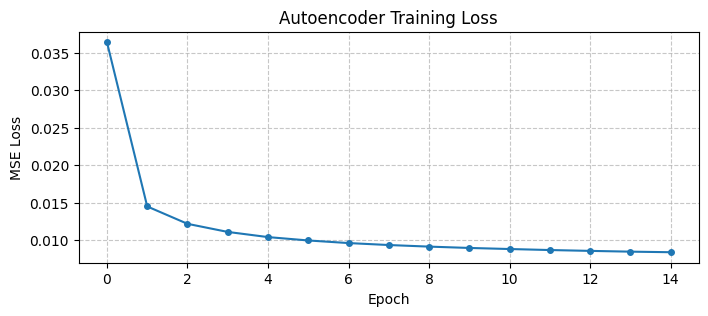

In [6]:
ae_model = ConvAutoencoder(latent_dim=32).to(device)
ae_losses = train_autoencoder(ae_model, train_loader, num_epochs=15)

plt.figure(figsize=(8, 3))
plt.plot(ae_losses, marker='o', markersize=4)
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('Autoencoder Training Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## Task 3.3 — Visualise Reconstructions

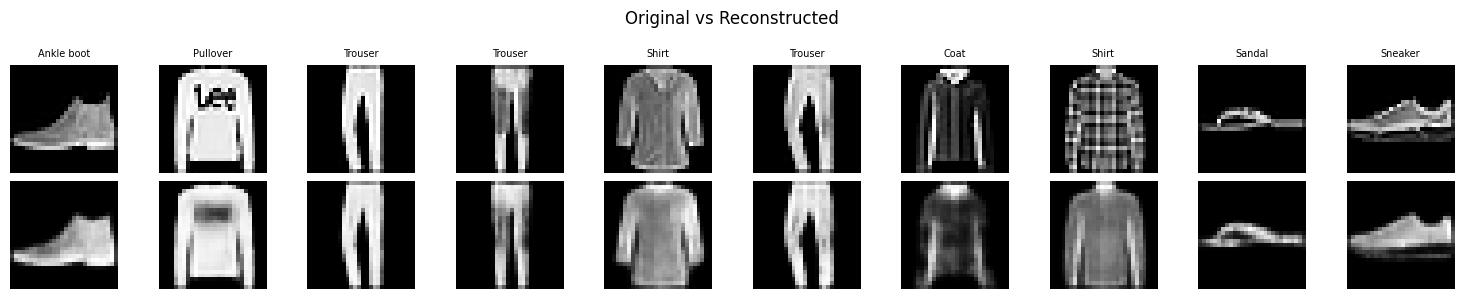

In [7]:
def visualise_reconstructions(model, dataset, n=10):
    model.eval()
    fig, axes = plt.subplots(2, n, figsize=(n * 1.5, 3))
    
    for i in range(n):
        img, label = dataset[i]
        img_device = img.unsqueeze(0).to(device)
        
        with torch.inference_mode():
            recon = model(img_device).cpu()
        
        axes[0, i].imshow(img.squeeze(), cmap='gray')
        axes[0, i].axis('off')
        if i == 0: axes[0, i].set_ylabel('Original', fontsize=10)
        axes[0, i].set_title(CLASS_NAMES[label], fontsize=7)
        
        axes[1, i].imshow(recon.squeeze(), cmap='gray')
        axes[1, i].axis('off')
        if i == 0: axes[1, i].set_ylabel('Reconstructed', fontsize=10)
    
    plt.suptitle('Original vs Reconstructed', fontsize=12)
    plt.tight_layout()
    plt.show()

visualise_reconstructions(ae_model, test_dataset)

### 🤔 Questions

1. What details are preserved in the reconstructions? What is lost?
2. Why are the reconstructions blurry? (Hint: think about what MSE loss optimises for)
3. Do some classes reconstruct better than others? Why?

*Double-click here to write your answers...*

## Task 3.4 — The Bottleneck Experiment: Compression vs Fidelity

What happens when we change the latent dimension? A smaller bottleneck forces more compression but loses more detail. A larger bottleneck preserves more detail but provides less compression.


--- Latent dim = 2 ---
  Epoch 1/10 — Loss: 0.061846
  Epoch 5/10 — Loss: 0.035523
  Epoch 10/10 — Loss: 0.033724

--- Latent dim = 8 ---
  Epoch 1/10 — Loss: 0.041122
  Epoch 5/10 — Loss: 0.017395
  Epoch 10/10 — Loss: 0.015857

--- Latent dim = 32 ---
  Epoch 1/10 — Loss: 0.030302
  Epoch 5/10 — Loss: 0.010103
  Epoch 10/10 — Loss: 0.008679

--- Latent dim = 128 ---
  Epoch 1/10 — Loss: 0.031302
  Epoch 5/10 — Loss: 0.007338
  Epoch 10/10 — Loss: 0.005362


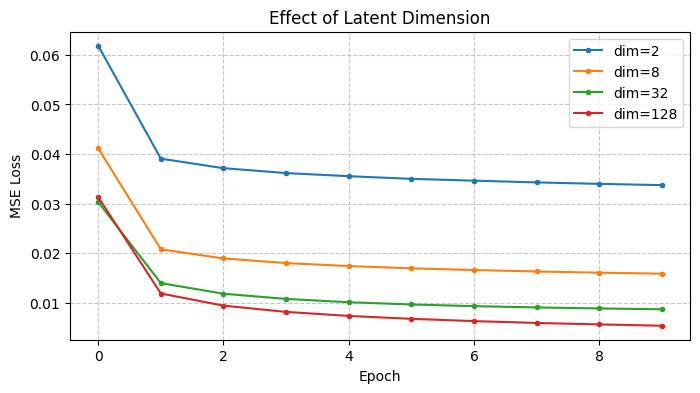

In [8]:
bottleneck_results = {}

for latent_dim in [2, 8, 32, 128]:
    print(f'\n--- Latent dim = {latent_dim} ---')
    model = ConvAutoencoder(latent_dim=latent_dim).to(device)
    losses = train_autoencoder(model, train_loader, num_epochs=10)
    bottleneck_results[latent_dim] = {'model': model, 'losses': losses}

# Plot loss curves
plt.figure(figsize=(8, 4))
for dim, res in bottleneck_results.items():
    plt.plot(res['losses'], label=f'dim={dim}', marker='o', markersize=3)
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('Effect of Latent Dimension')
plt.legend(); plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

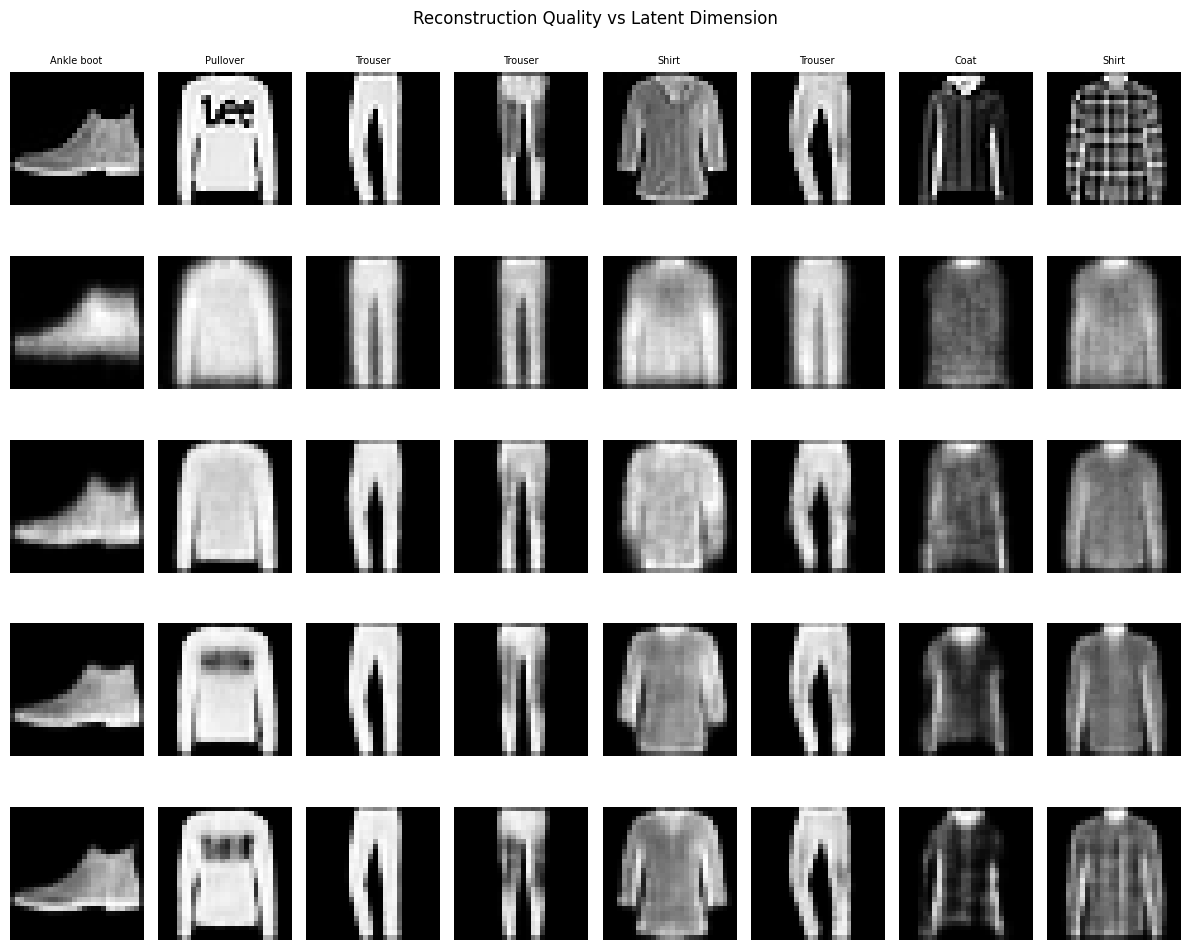

In [9]:
# Compare reconstructions across latent dimensions
fig, axes = plt.subplots(len(bottleneck_results) + 1, 8, figsize=(12, 2 * (len(bottleneck_results) + 1)))

# Original row
for i in range(8):
    img, label = test_dataset[i]
    axes[0, i].imshow(img.squeeze(), cmap='gray')
    axes[0, i].axis('off')
    axes[0, i].set_title(CLASS_NAMES[label], fontsize=7)
axes[0, 0].set_ylabel('Original', fontsize=9)

# Reconstruction rows
for row, (dim, res) in enumerate(bottleneck_results.items(), 1):
    model = res['model']
    model.eval()
    for i in range(8):
        img, _ = test_dataset[i]
        with torch.inference_mode():
            recon = model(img.unsqueeze(0).to(device)).cpu()
        axes[row, i].imshow(recon.squeeze(), cmap='gray')
        axes[row, i].axis('off')
    axes[row, 0].set_ylabel(f'dim={dim}', fontsize=9)

plt.suptitle('Reconstruction Quality vs Latent Dimension', fontsize=12)
plt.tight_layout()
plt.show()

### 🤔 Questions 

1. What happens to reconstruction quality as `latent_dim` decreases?
2. With `latent_dim=2`, how much compression are we achieving? (from 784 pixels to 2 numbers)
3. What trade-off exists between compression and fidelity?
4. At what latent dimension do the reconstructions become "good enough"? How would you define "good enough"?

*Double-click here to write your answers...*

## Task 3.5 — Exploring the Latent Space

Does the autoencoder learn a **meaningful** latent space? If similar items are encoded to nearby points, the latent space has useful structure.

We'll use the `latent_dim=2` model to directly plot the 2D latent space, and t-SNE to visualise higher-dimensional latent spaces.

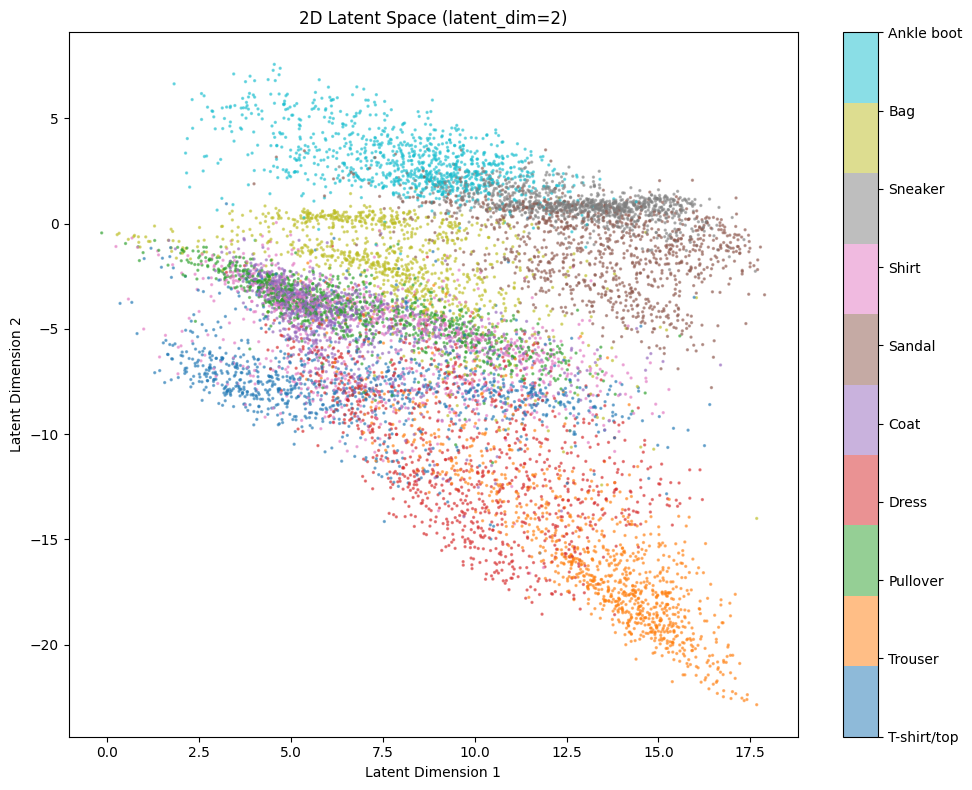

In [10]:
# Direct 2D visualisation (using the dim=2 model)
model_2d = bottleneck_results[2]['model']
model_2d.eval()

# Encode a subset of the test set
all_latents, all_labels = [], []
with torch.inference_mode():
    for images, labels in DataLoader(test_dataset, batch_size=256):
        z = model_2d.encode(images.to(device)).cpu().numpy()
        all_latents.append(z)
        all_labels.append(labels.numpy())

all_latents = np.vstack(all_latents)
all_labels = np.concatenate(all_labels)

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(all_latents[:, 0], all_latents[:, 1],
                     c=all_labels, cmap='tab10', s=2, alpha=0.5)
cbar = plt.colorbar(scatter, ax=ax, ticks=range(10))
cbar.ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Latent Dimension 1')
ax.set_ylabel('Latent Dimension 2')
ax.set_title('2D Latent Space (latent_dim=2)')
plt.tight_layout()
plt.show()

Running t-SNE (this may take a minute)...


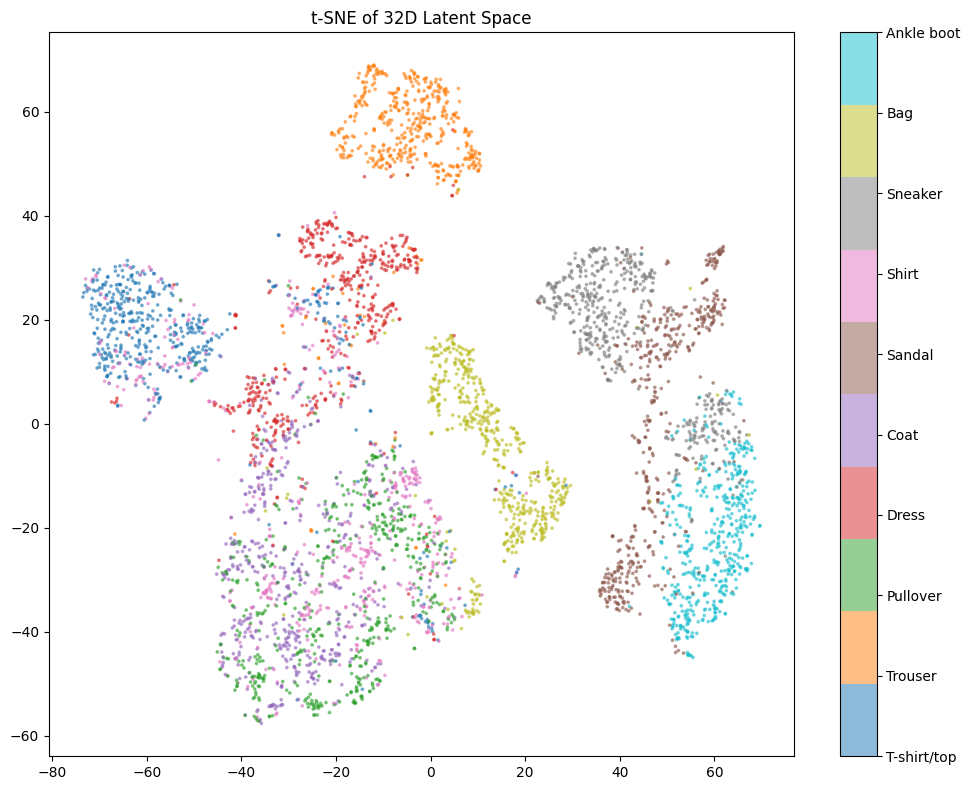

In [11]:
# t-SNE visualisation of the 32-dim latent space
model_32 = bottleneck_results[32]['model']
model_32.eval()

latents_32, labels_32 = [], []
with torch.inference_mode():
    for images, labels in DataLoader(test_dataset, batch_size=256):
        z = model_32.encode(images.to(device)).cpu().numpy()
        latents_32.append(z)
        labels_32.append(labels.numpy())

latents_32 = np.vstack(latents_32)
labels_32 = np.concatenate(labels_32)

# t-SNE reduction from 32D to 2D
print('Running t-SNE (this may take a minute)...')
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
latents_2d = tsne.fit_transform(latents_32[:5000])  # subsample for speed

fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(latents_2d[:, 0], latents_2d[:, 1],
                     c=labels_32[:5000], cmap='tab10', s=3, alpha=0.5)
cbar = plt.colorbar(scatter, ax=ax, ticks=range(10))
cbar.ax.set_yticklabels(CLASS_NAMES)
ax.set_title('t-SNE of 32D Latent Space')
plt.tight_layout()
plt.show()

### 🤔 Questions

1. Do similar classes cluster together in the latent space? Which classes overlap?
2. Compare the 2D latent space (directly learned) with the t-SNE of the 32D space. Which shows better separation? Why?
3. How could these latent representations be used for downstream tasks? (e.g., clustering, retrieval, anomaly detection)

*Double-click here to write your answers...*

---
# Part 4: Generative Adversarial Networks — GANs 

## The Core Idea

A GAN consists of two competing networks:

| Network | Goal | Analogy |
|---|---|---|
| **Generator (G)** | Create realistic fake images from random noise | Forger trying to create convincing paintings |
| **Discriminator (D)** | Distinguish real images from fake | Art detective trying to catch fakes |

They are trained in an **adversarial game**:
- G tries to fool D by generating increasingly realistic images
- D tries to catch G by getting better at spotting fakes
- In equilibrium, G produces images indistinguishable from real data

The GAN objective (minimax game):

$$\min_G \max_D \; \mathbb{E}_{x \sim p_{data}}[\log D(x)] + \mathbb{E}_{z \sim p_z}[\log(1 - D(G(z)))]$$

## Task 4.1 — Build the Generator and Discriminator

In [15]:
LATENT_DIM_GAN = 100

class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM_GAN):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 28 * 28),
            nn.Tanh(),  # output in [-1, 1]
        )
    
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
            nn.Sigmoid(),
        )
    
    def forward(self, x):
        return self.net(x)

print(f'Generator params:     {sum(p.numel() for p in Generator().parameters()):,}')
print(f'Discriminator params: {sum(p.numel() for p in Discriminator().parameters()):,}')

Generator params:     1,489,936
Discriminator params: 533,505


👉 **Design choices explained:**
- **Generator uses `Tanh`** — outputs in [-1, 1], which matches normalised images
- **Generator uses `BatchNorm`** — stabilises training (a trick from the DCGAN paper)
- **Discriminator uses `LeakyReLU(0.2)`** — prevents dying neurons; standard in GAN discriminators
- **Discriminator uses `Dropout`** — prevents the discriminator from becoming too strong too quickly
- **Discriminator outputs `Sigmoid`** — probability that the input is real

## Task 4.2 — GAN Training Loop

In [16]:
# Normalise data to [-1, 1] to match Generator's Tanh output
gan_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),  # maps [0,1] to [-1,1]
])
gan_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=gan_transform)
gan_loader = DataLoader(gan_dataset, batch_size=128, shuffle=True)

In [17]:
def train_gan(generator, discriminator, dataloader, num_epochs=30, lr=2e-4):
    criterion = nn.BCELoss()
    g_optimizer = optim.Adam(generator.parameters(), lr=lr, betas=(0.5, 0.999))
    d_optimizer = optim.Adam(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))
    
    g_losses, d_losses = [], []
    fixed_noise = torch.randn(64, LATENT_DIM_GAN, device=device)  # for tracking progress
    sample_images = []  # store generated samples periodically
    
    for epoch in range(num_epochs):
        g_loss_epoch, d_loss_epoch = 0.0, 0.0
        
        for real_images, _ in dataloader:
            batch_size = real_images.size(0)
            real_images = real_images.to(device)
            
            real_labels = torch.ones(batch_size, 1, device=device) * 0.9  # label smoothing
            fake_labels = torch.zeros(batch_size, 1, device=device)
            
            # --- Train Discriminator ---
            d_optimizer.zero_grad()
            
            # Real images
            d_real_out = discriminator(real_images)
            d_real_loss = criterion(d_real_out, real_labels)
            
            # Fake images
            z = torch.randn(batch_size, LATENT_DIM_GAN, device=device)
            fake_images = generator(z).detach()  # detach — don't train G here
            d_fake_out = discriminator(fake_images)
            d_fake_loss = criterion(d_fake_out, fake_labels)
            
            d_loss = d_real_loss + d_fake_loss
            d_loss.backward()
            d_optimizer.step()
            
            # --- Train Generator ---
            g_optimizer.zero_grad()
            
            z = torch.randn(batch_size, LATENT_DIM_GAN, device=device)
            fake_images = generator(z)
            d_out = discriminator(fake_images)
            g_loss = criterion(d_out, torch.ones(batch_size, 1, device=device))  # G wants D to say "real"
            
            g_loss.backward()
            g_optimizer.step()
            
            g_loss_epoch += g_loss.item()
            d_loss_epoch += d_loss.item()
        
        g_losses.append(g_loss_epoch / len(dataloader))
        d_losses.append(d_loss_epoch / len(dataloader))
        
        # Save samples periodically
        if (epoch + 1) % 5 == 0 or epoch == 0:
            generator.eval()
            with torch.inference_mode():
                samples = generator(fixed_noise).cpu()
            sample_images.append((epoch + 1, samples))
            generator.train()
            print(f'  Epoch {epoch+1}/{num_epochs} — G Loss: {g_losses[-1]:.4f}, D Loss: {d_losses[-1]:.4f}')
    
    return g_losses, d_losses, sample_images

In [18]:
generator = Generator().to(device)
discriminator = Discriminator().to(device)

g_losses, d_losses, gan_samples = train_gan(generator, discriminator, gan_loader, num_epochs=30)

  Epoch 1/30 — G Loss: 1.4518, D Loss: 1.0866
  Epoch 5/30 — G Loss: 1.1358, D Loss: 1.2866
  Epoch 10/30 — G Loss: 0.9583, D Loss: 1.3386
  Epoch 15/30 — G Loss: 0.9389, D Loss: 1.3451
  Epoch 20/30 — G Loss: 0.9036, D Loss: 1.3518
  Epoch 25/30 — G Loss: 0.8639, D Loss: 1.3626
  Epoch 30/30 — G Loss: 0.8511, D Loss: 1.3680


## Task 4.3 — Analyse GAN Training

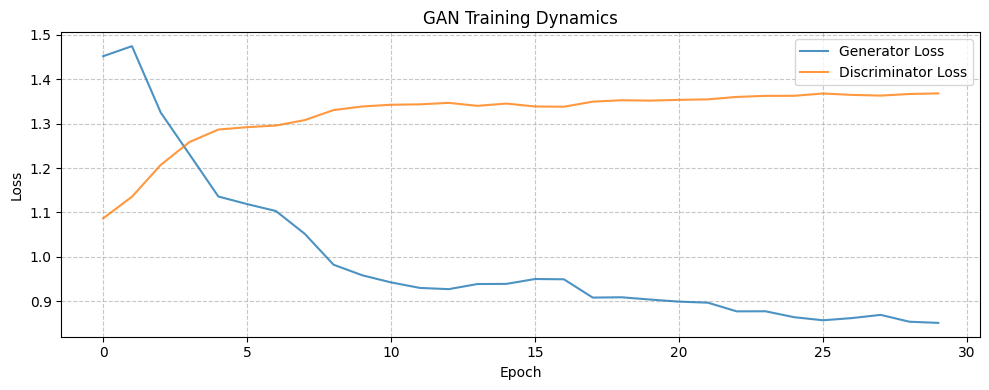

In [19]:
# Plot G and D losses
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(g_losses, label='Generator Loss', alpha=0.8)
ax.plot(d_losses, label='Discriminator Loss', alpha=0.8)
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.set_title('GAN Training Dynamics')
ax.legend(); ax.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Task 4.4 — Visualise Generated Images Over Time

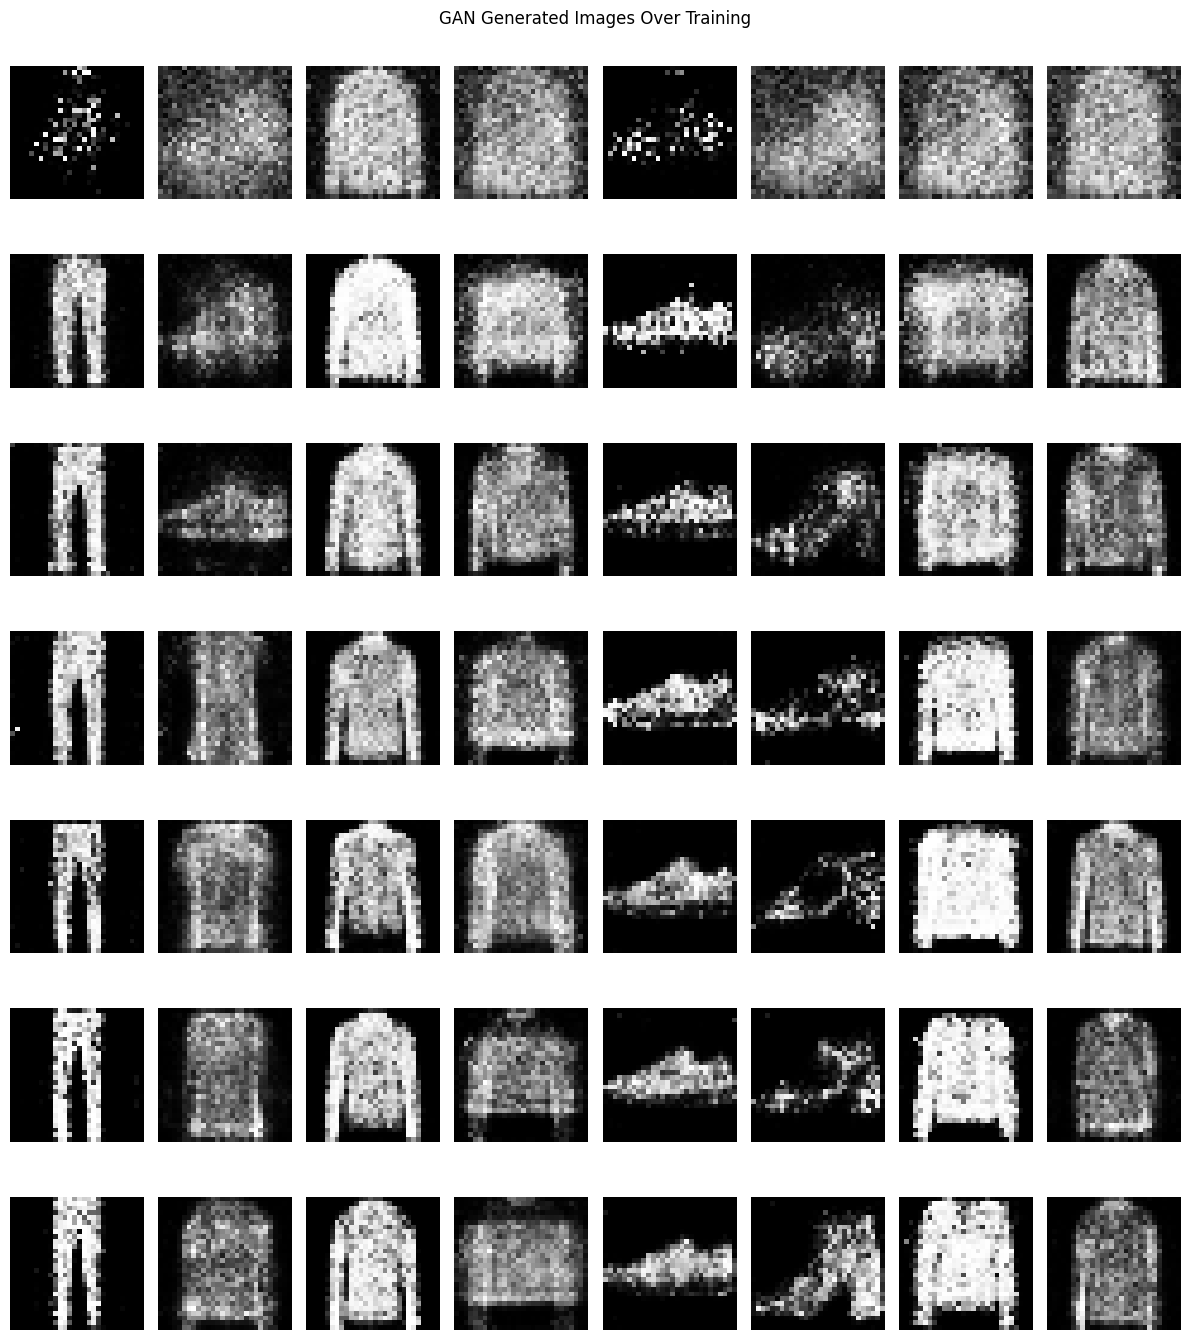

In [20]:
# Show how generated images improve during training
n_snapshots = len(gan_samples)
fig, axes = plt.subplots(n_snapshots, 8, figsize=(12, 2 * n_snapshots))

for row, (epoch, samples) in enumerate(gan_samples):
    for col in range(8):
        img = samples[col].squeeze().numpy() * 0.5 + 0.5  # denormalise [-1,1] → [0,1]
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].axis('off')
    axes[row, 0].set_ylabel(f'Epoch {epoch}', fontsize=9)

plt.suptitle('GAN Generated Images Over Training', fontsize=12)
plt.tight_layout()
plt.show()

## GAN Failure Modes

GANs are notoriously difficult to train. Common problems:

| Problem | Symptom | Cause |
|---|---|---|
| **Mode collapse** | Generator produces the same image repeatedly | G finds one output that fools D and never moves beyond it |
| **Discriminator dominance** | G loss increases, images don't improve | D becomes too strong; G gets no useful gradient signal |
| **Training instability** | Losses oscillate wildly | Learning rates too high, or G and D update rates unbalanced |
| **No convergence** | Losses don't settle, images remain noisy | Architecture or hyperparameter issues |

### 🤔 Questions

1. How do the generated images change over training? What emerges first — shapes or textures?
2. Look at the G and D loss curves. Are they balanced, or does one dominate?
3. Do you see evidence of mode collapse (many similar-looking generated images)?
4. Why must the generator and discriminator remain roughly balanced during training?
5. Why did we use label smoothing (0.9 instead of 1.0 for real labels)?

*Double-click here to write your answers...*

---
# Part 5: Diffusion Models

## The Core Idea

Diffusion models work fundamentally differently from GANs:

1. **Forward process (fixed):** Gradually add Gaussian noise to an image until it becomes pure noise
2. **Reverse process (learned):** Train a neural network to gradually remove noise, step by step

```
Clean image → slightly noisy → more noisy → ... → pure noise
     ←  denoise  ←  denoise  ← ... ←  denoise
```

At generation time, start from pure noise and iteratively denoise to produce a clean image.

We won't build a full diffusion model (it requires hundreds of denoising steps), have a look at the example done in the lectuer. 

## Visualise the Noise Corruption Process

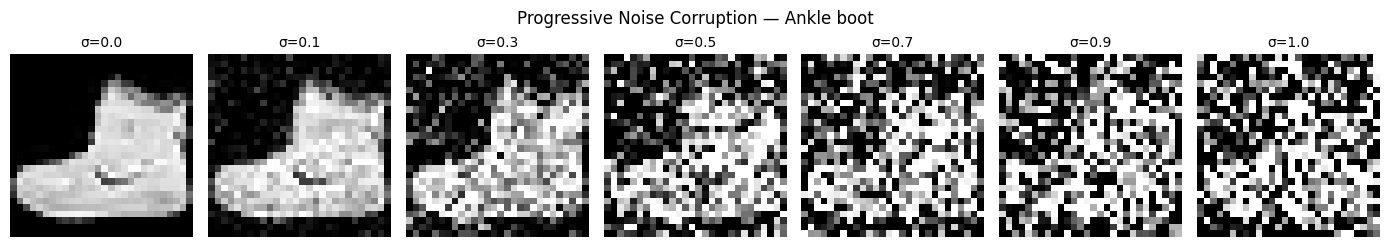

In [12]:
# Show progressive noise corruption
image, label = train_dataset[0]
noise_levels = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]

fig, axes = plt.subplots(1, len(noise_levels), figsize=(14, 2.5))
for i, sigma in enumerate(noise_levels):
    noisy = image + sigma * torch.randn_like(image)
    noisy = torch.clamp(noisy, 0, 1)
    axes[i].imshow(noisy.squeeze(), cmap='gray')
    axes[i].set_title(f'σ={sigma}', fontsize=10)
    axes[i].axis('off')

plt.suptitle(f'Progressive Noise Corruption — {CLASS_NAMES[label]}', fontsize=12)
plt.tight_layout()
plt.show()

## Build a Denoising Autoencoder

A denoising autoencoder receives a **noisy** image as input but is trained to reconstruct the **clean** original. This is the fundamental operation that diffusion models perform — learning to remove noise.

The key modification from Part 2: during training, we add noise to the input but compare the output to the **clean** target.


**Do this as homework**

In [22]:
# Build and train a denoising autoencoder

## Connecting to Full Diffusion Models

What we built is a **single-step** denoiser. Real diffusion models (DDPM, Stable Diffusion) extend this idea:

1. Train the denoiser to handle **many different noise levels** (not just σ=0.3)
2. At generation time, start from pure noise and **iteratively denoise** in small steps (typically 50–1000 steps)
3. Each step removes a small amount of noise, gradually revealing a clean image

The iterative process is slower than GANs (which generate in one step) but produces higher quality and more diverse outputs.

### 🤔 Questions

1. How well does the denoising autoencoder recover the clean images?
2. How does this relate to the full diffusion model process? What's the key difference?
3. Why might iterative denoising (many small steps) produce better results than one-step generation?

*Double-click here to write your answers...*

---
# Part 6: Comparing Generative Models 

### Fill in the comparison table based on your experiments:

| Property           | Autoencoder                       | GAN                             | Diffusion                   |
| ------------------ | --------------------------------- | ------------------------------- | --------------------------- |
| Training Stability | Stable                            | Unstable                        | Stable                      |
| Sample Diversity   | N/A (reconstructs inputs)         | Risk of mode collapse           | High                        |
| Image Quality      | Often blurry (MSE reconstruction) | Sharp but may contain artifacts | High quality                |
| Generation Speed   | Fast (one forward pass)           | Fast (one forward pass)         | Slow (many denoising steps) |
| Latent Space       | Structured and interpretable      | Often entangled                 | Usually not explicit        |
| Ease of Training   | Easy                              | Difficult                       | Moderate                    |


Property                  Autoencoder          GAN                  Diffusion
================================================================================
Training stability        Stable               Unstable             Stable
Sample diversity          N/A (reconstruct)    Risk of collapse     High
Image quality             Blurry (MSE)         Sharp but artifacts  High quality
Generation speed          Fast (one pass)      Fast (one pass)      Slow (many steps)
Latent space              Structured           Entangled            Not explicit
Ease of training          Easy                 Difficult            Moderate

### 🤔 Questions

1. Why are autoencoder reconstructions typically blurry? (Hint: what does MSE loss optimise?)
2. Why do GANs produce sharper images than autoencoders?
3. Why have diffusion models become the dominant generative model despite being slow?
4. If you needed to generate diverse, high-quality fashion designs, which model family would you choose?

*Double-click here to write your answers...*

---
# Part 7: Mini Challenge 

Choose **one** option:

### Option A — Improve the Autoencoder
- Add skip connections (U-Net style)
- Try a deeper encoder
- Use perceptual loss instead of MSE
- Build a variational autoencoder (VAE)

### Option B — Improve the GAN
- Convert to a convolutional GAN (DCGAN) — use `ConvTranspose2d` in the generator
- Add conditional labels (class-conditional generation)
- Experiment with different learning rates or training ratios (train D more often than G)

### Option C — Latent Space Exploration
- Perform **latent interpolation**: encode two images, linearly interpolate their latent vectors, and decode the intermediate points
- Use autoencoder latent vectors for **nearest-neighbour retrieval**: find the most similar images to a query
- Train a simple classifier on latent vectors and compare accuracy to a CNN on raw pixels

In [ ]:
# Your code here
# ...

---
# Part 8: Reflection

1. What is the difference between reconstruction, generation, and representation learning? How do autoencoders, GANs, and diffusion models relate to each?
2. Why are latent spaces important? What makes a "good" latent space?
3. Why are GANs unstable to train? What makes the adversarial setup fundamentally challenging?
4. Why have diffusion models become the dominant paradigm in image generation despite being slower than GANs?
5. What was the most interesting or surprising result you observed in this lab?

*Double-click here to write your reflection...*

---
# Bonus (Optional)

- **Variational Autoencoder (VAE):** Add the KL divergence loss to regularise the latent space, enabling sampling
- **DCGAN:** Replace the fully-connected GAN with convolutional layers
- **Latent arithmetic:** With a VAE, try latent vector arithmetic (e.g., "shirt" + "stripe pattern" = "striped shirt")
- **Fréchet Inception Distance (FID):** Implement FID to quantitatively evaluate generated image quality
- **Multi-noise denoiser:** Train the denoising autoencoder on multiple noise levels simultaneously



---

## 🔑 Key Takeaway

Deep learning models can do far more than classification. By learning meaningful latent representations and modelling data distributions, generative models can compress, reconstruct, and synthesise complex visual data. The progression from autoencoders (simple, stable) to GANs (powerful, unstable) to diffusion models (high quality, slow) mirrors the field's development — each generation of models addresses the limitations of the previous one.